In [9]:
import numpy as np
import pandas as pd
from  pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns   
from scipy.stats import chi2_contingency
from scipy .stats import f_oneway


dataDirectoty = Path.cwd().parents[1] / 'data'

trainData = pd.read_csv(dataDirectoty / 'train.csv')
testData = pd.read_csv(dataDirectoty / 'test.csv')

In [3]:
print(trainData.duplicated().sum())

0


In [4]:
print(trainData.head(10))

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   
5            6         0       3   
6            7         0       1   
7            8         0       3   
8            9         1       3   
9           10         1       2   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   
5                                   Moran, Mr. James    male   NaN      0   
6                            McCarthy, Mr. Timothy J    male  54

In [5]:
print(trainData.info()) 

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB
None


In [6]:
print(trainData.describe())

       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    0.523008   
std     257.353842    0.486592    0.836071   14.526497    1.102743   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     223.500000    0.000000    2.000000   20.125000    0.000000   
50%     446.000000    0.000000    3.000000   28.000000    0.000000   
75%     668.500000    1.000000    3.000000   38.000000    1.000000   
max     891.000000    1.000000    3.000000   80.000000    8.000000   

            Parch        Fare  
count  891.000000  891.000000  
mean     0.381594   32.204208  
std      0.806057   49.693429  
min      0.000000    0.000000  
25%      0.000000    7.910400  
50%      0.000000   14.454200  
75%      0.000000   31.000000  
max      6.000000  512.329200  


## Feature analysis

### Categorical features

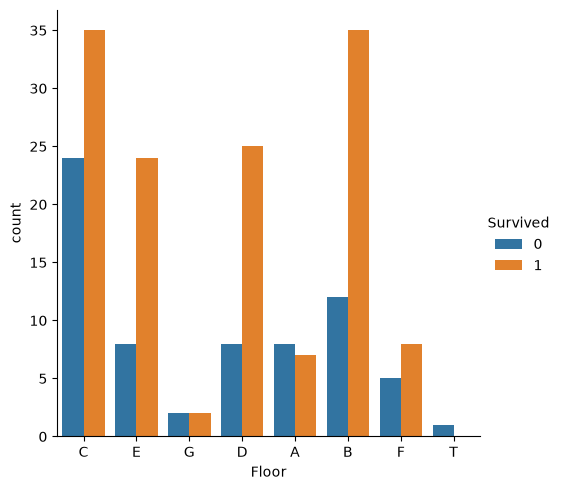

In [7]:
trainDataWithFloorColumn = trainData
trainDataWithFloorColumn['Floor'] = trainData['Cabin'].str[0]
sns.catplot(data=trainDataWithFloorColumn, kind='count', x='Floor', hue='Survived')
plt.show()

Frequencies:  Embarked
S      0.722783
C      0.188552
Q      0.086420
NaN    0.002245
Name: proportion, dtype: float64
Cardinality(Not NaN):  3
H0 = Embarked and survived are independent
H1 = Embarked and survived are dependent
Rechazamos H0


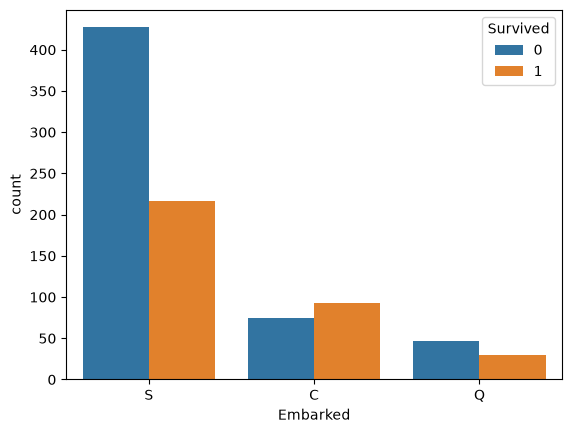

In [15]:
print("Frequencies: ", trainData['Embarked'].value_counts(normalize=True, dropna=False))
print("Cardinality(Not NaN): ", trainData['Embarked'].nunique())

print("H0 = Embarked and survived are independent")
print("H1 = Embarked and survived are dependent")

alpha = 0.05

chi2, p_value, dof, exp = chi2_contingency(pd.crosstab(trainData['Embarked'], trainData['Survived']))


print("Rechazamos H0" if p_value <= 0.05 else "No rechazamos H0")

sns.countplot(data=trainData, x="Embarked", hue="Survived")
plt.show()





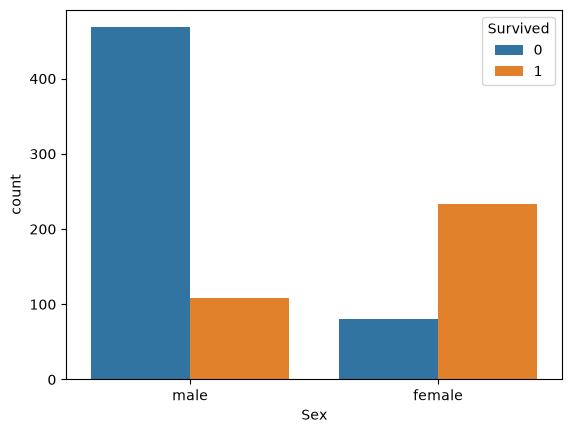

In [9]:
sns.countplot(data=trainData, x='Sex', hue='Survived')
plt.show()

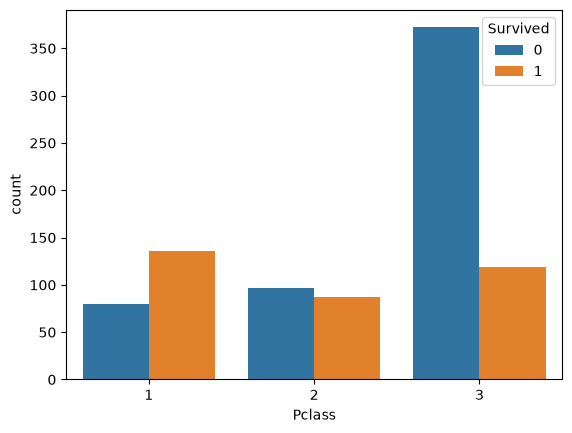

In [10]:
sns.countplot(data=trainData, x='Pclass', hue='Survived')
plt.show()

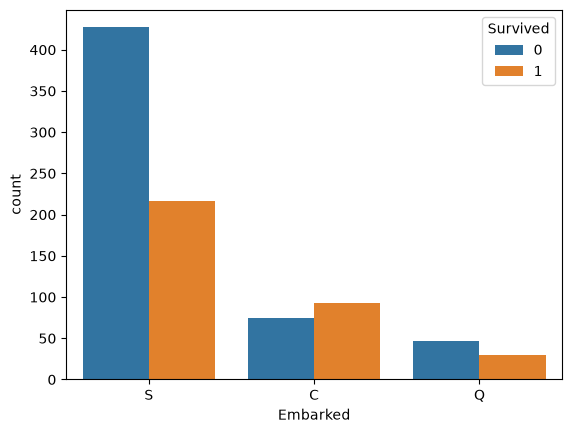

In [11]:
sns.countplot(data=trainData, x='Embarked', hue='Survived')
plt.show()

### Numerical features

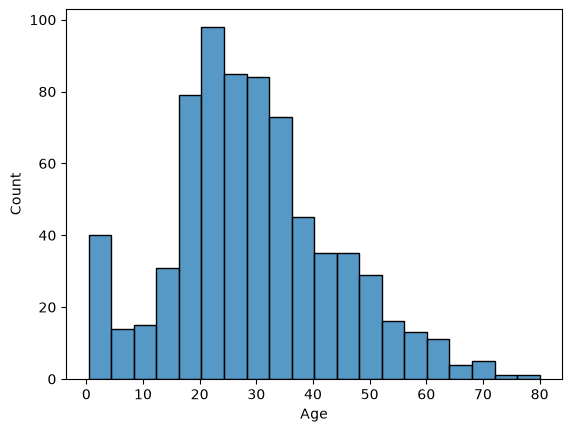

In [12]:
sns.histplot(data=trainData, x="Age")
plt.show()

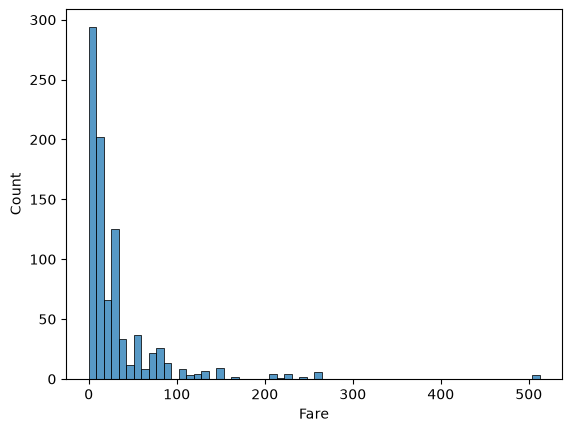

In [13]:
sns.histplot(data=trainData, x='Fare')
plt.show()

### Embarking against categotical features

In [16]:
categorical_columns_to_compare = ['Pclass', 'Sex']
print("Chi² tests")
print("--------------------")
for feature in categorical_columns_to_compare:
    print(f"H0: Embarked and {feature} are independent")
    print(f"H1: Embarked and {feature} are dependent")

    data = trainData[['Embarked', feature]].dropna()
    chi2, p_value, dof, exp = chi2_contingency(pd.crosstab(trainData['Embarked'], data[feature]))
    print("Rechazamos H0" if p_value <= 0.05 else "No rechazamos H0")
    print(f"P valor: {p_value}")
    print("--------------------")

    

Chi² tests
--------------------
H0: Embarked and Pclass are independent
H1: Embarked and Pclass are dependent
Rechazamos H0
P valor: 8.435267819894384e-26
--------------------
H0: Embarked and Sex are independent
H1: Embarked and Sex are dependent
Rechazamos H0
P valor: 0.0012585245232290144
--------------------


### Embarking against numerical features

In [17]:
numerical_columns_to_compare = ['Age', 'Fare']
print("ANOVA tests")
print("--------------------")
for feature in numerical_columns_to_compare:
    print(f"H0: Embarked and {feature} are independent")
    print(f"H1: Embarked and {feature} are dependent")

    data = trainData[['Embarked', feature]].dropna()
    grupos = [g[feature].values for _, g in data.groupby("Embarked")]
    F, p_value = f_oneway(*grupos)

    print("Rechazamos H0" if p_value <= 0.05 else "No rechazamos H0")
    print(f"F: {F}, p value: {p_value}")
    print("--------------------")
    



ANOVA tests
--------------------
H0: Embarked and Age are independent
H1: Embarked and Age are dependent
No rechazamos H0
F: 0.6366398124910263, p value: 0.5293693792569866
--------------------
H0: Embarked and Fare are independent
H1: Embarked and Fare are dependent
Rechazamos H0
F: 38.140305200112664, p value: 1.2896450252637108e-16
--------------------
